# Full-text re-check on an evenly covered corpus (v3)

Tracking issue: [#7](https://github.com/fulaibaowang/dictycite/issues/7).

The paper's full-text experiment (Fig 5 and Table S2 of the accepted manuscript, made in
`report_7a.py` §14) adds chunked full text (corpus v2) to the abstract corpus. v2 covers most
cited articles but few uncited ones (see `docs/FULLTEXT.md`), so cited articles gained
full-text chunks while most distractors did not. This notebook repeats the comparison on a
newer full-text corpus (v3) whose coverage is near-complete for cited and uncited articles
alike, and asks:

1. Do the paper's full-text findings hold?
2. Does full text help overall?
3. Does full text still help once queries use gene-aware expansion (7d: +synonyms,
   +synonyms & products)?

**Protocol** — the paper's v2 run, changed only where the corpus requires it: hybrid BM25 +
MedEmbed retrieval fused by RRF (k=60, equal weights), rerank of the top 2000 candidates,
post-rerank fusion with pools R300/H300, k=60. Rerankers BGE-m3 and MedCPT. Every run's
`retrieval/fusion/best_config.json` confirms k=60 with 1:1 weights. The abstract-only arms
were rerun with the same settings. Configs:
`scripts/private_scripts/hpc_scripts/frida/config_frida_fulltext_v3_*.env`.

**Scoring** — as in `report_7a.py` §14: chunk docnos (`{pmid}#...`) collapse to PMIDs by
first occurrence (max-pool); claims are stratified by the evidence label of their cited
articles; has-PDF / no-PDF splits each claim–stratum entry by whether any cited article
carrying that label has full-text chunks. Deltas are in percentage points with 95% paired
bootstrap CIs (B = 10,000, seed 0).

**Inputs** (gitignored, under `output/`): `workflow_frida_fulltext_v3_<arm>_<reranker>/`
(fusion run + post-rerank fusion run per arm), the paper's runs
(`workflow_vega_7a_public_goldset_*`, `workflow_frida_7a_public_goldset_chunked_v2*`), the v2
chunk list `pdf_extraction/v2/chunks.jsonl` and the v3 chunked-PMID list
`fulltext_v3/v3_pmids.json`.

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

plt.rcParams["axes.grid"] = False
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["xtick.labelsize"] = 12
plt.rcParams["ytick.labelsize"] = 12

base_dir = Path.cwd().resolve()
if base_dir.name == "notebooks":
    base_dir = base_dir.parent
OUT = base_dir / "output"
FIG_DIR = OUT / "fulltext_v3" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

GOLD = {
    "7a": OUT / "dicty_gold_build" / "7a_dicty_gold_llm_public.jsonl",
    "7d": OUT / "dicty_gold_build" / "7d_dicty_gold_query_expansion_benchmark.jsonl",
}
LEVELS = ["abstract_supports_detail", "abstract_supports_core", "abstract_insufficient"]
LEVEL_LABELS = {
    "abstract_supports_detail": "Abstract supports detail",
    "abstract_supports_core": "Abstract supports core",
    "abstract_insufficient": "Abstract insufficient",
}
SHORT = {"abstract_supports_detail": "Detail", "abstract_supports_core": "Core",
         "abstract_insufficient": "Insufficient"}
RERANKERS = {"bge": "BGE-m3", "medcpt": "MedCPT"}
B_BOOT, SEED = 10_000, 0


def v3_dir(arm, rr):
    return OUT / f"workflow_frida_fulltext_v3_{arm}_{rr}"


# Fusion run (first stage) and post-rerank fusion run (final ranking) per system.
RUNS = {}
for rr in RERANKERS:
    for arm in ["7a_abs", "7a_v3", "7d_syn_abs", "7d_syn_v3", "7d_synprod_abs", "7d_synprod_v3"]:
        d = v3_dir(arm, rr)
        RUNS[(arm, rr)] = (
            next((d / "retrieval/fusion/runs").glob("*_top5000.tsv")),
            next((d / "rerank/post_rerank_fusion/runs").glob("*poolR300_poolH300_k60.tsv")),
        )
_vega = OUT / "workflow_vega_7a_public_goldset_both_routes"
_v2 = OUT / "workflow_frida_7a_public_goldset_chunked_v2"
_v2m = OUT / "workflow_frida_7a_public_goldset_chunked_v2_rerank_medcpt"
_split = "best_rrf_7a_dicty_gold_llm_public_top5000"
RUNS[("paper_abs", "bge")] = (_vega / f"retrieval/fusion/runs/{_split}.tsv",
                              _vega / f"rerank/post_rerank_fusion_snippet/runs/{_split}_rrf_poolR200_poolH200_k60.tsv")
RUNS[("paper_v2", "bge")] = (_v2 / f"retrieval/fusion/runs/{_split}.tsv",
                             _v2 / f"rerank/post_rerank_fusion/runs/{_split}_rrf_poolR300_poolH300_k60.tsv")
RUNS[("paper_v2", "medcpt")] = (_v2m / f"retrieval/fusion/runs/{_split}.tsv",
                                _v2m / f"rerank/post_rerank_fusion/runs/{_split}_rrf_poolR300_poolH300_k60.tsv")
_missing = [p for pair in RUNS.values() for p in pair if not p.is_file()]
assert not _missing, _missing
for d in sorted(OUT.glob("workflow_frida_fulltext_v3_*")):
    cfg = json.loads((d / "retrieval/fusion/best_config.json").read_text()) \
        if (d / "retrieval/fusion/best_config.json").is_file() else None
    if cfg:
        assert (cfg["k_rrf"], cfg["w_bm25"], cfg["w_dense"]) == (60.0, 1.0, 1.0), d
print(f"{len(RUNS)} systems found")

15 systems found


### Loaders, metrics, bootstrap

In [2]:
_run_cache = {}


def load_run(path, keep_pmids=None):
    """Run TSV -> {qid: [pmid, ...]} by max-pool. With keep_pmids, full-text chunks of other
    PMIDs are dropped first (abstracts, `{pmid}#abstract` or bare `{pmid}`, are always kept)."""
    key = (path, id(keep_pmids))
    if key in _run_cache:
        return _run_cache[key]
    df = pd.read_csv(path, sep="\t", dtype=str)
    q, d = "qid", ("docno" if "docno" in df.columns else "docid")
    if "rank" in df.columns:
        df["rank"] = df["rank"].astype(int)
        df = df.sort_values([q, "rank"], kind="stable")
    pm = df[d].str.split("#", n=1).str[0]
    if keep_pmids is not None:
        is_abs = ~df[d].str.contains("#") | df[d].str.endswith("#abstract")
        df, pm = df[is_abs | pm.isin(keep_pmids)], pm[is_abs | pm.isin(keep_pmids)]
    out = {}
    for qid, g in pm.groupby(df[q], sort=False):
        out[str(qid)] = list(dict.fromkeys(g))
    _run_cache[key] = out
    return out


def system(name, rr, keep_pmids=None):
    ret, fin = RUNS[(name, rr)]
    return load_run(ret, keep_pmids), load_run(fin, keep_pmids)


def qrels(split):
    by_level, by_claim = {}, {}
    for line in open(GOLD[split]):
        r = json.loads(line)
        qid = str(r["query_id"])
        for doc in r.get("docs") or []:
            p = str(doc.get("pmid") or "")
            if p:
                by_level.setdefault(doc.get("evidence_level"), {}).setdefault(qid, set()).add(p)
                by_claim.setdefault(qid, set()).add(p)
    return by_level, by_claim


def mrr_at(docs, rels, k):
    for i, d in enumerate(docs[:k], 1):
        if d in rels:
            return 1.0 / i
    return 0.0


def recall_at(docs, rels, k):
    return sum(d in rels for d in docs[:k]) / len(rels)


def paired(q, run_a, run_b, fn, k):
    """Mean of A, mean of B, and B−A in points with a 95% paired-bootstrap CI."""
    qs = [x for x in q if x in run_a and x in run_b]
    a = np.array([fn(run_a[x], q[x], k) for x in qs])
    b = np.array([fn(run_b[x], q[x], k) for x in qs])
    diff = b - a
    rng = np.random.default_rng(SEED)
    boot = diff[rng.integers(0, diff.size, (B_BOOT, diff.size))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return dict(n=len(qs), a=a.mean(), b=b.mean(), d=diff.mean() * 100, lo=lo * 100, hi=hi * 100,
                up=(diff > 0).mean() * 100, down=(diff < 0).mean() * 100)


def strata(split, cov=None, qids=None):
    """{(stratum, part): qrels}; part is all / has-PDF / no-PDF (the latter two need cov)."""
    by_level, by_claim = qrels(split)
    out = {}
    for lvl in LEVELS:
        q = {x: p for x, p in by_level.get(lvl, {}).items() if qids is None or x in qids}
        out[(SHORT[lvl], "all")] = q
        if cov is not None:
            out[(SHORT[lvl], "has-PDF")] = {x: p & cov for x, p in q.items() if p & cov}
            out[(SHORT[lvl], "no-PDF")] = {x: p for x, p in q.items() if not p & cov}
    out[("All claims", "all")] = {x: p for x, p in by_claim.items() if qids is None or x in qids}
    return out


def compare(base, other, split="7a", cov=None, qids=None, parts=("all", "has-PDF", "no-PDF")):
    """Table S2-style rows: R@1000 and MRR@10 of base vs other, per stratum and coverage part."""
    (ra, fa), (rb, fb) = base, other
    rows = []
    for (stratum, part), q in strata(split, cov, qids).items():
        if part not in parts and stratum != "All claims":
            continue
        r = paired(q, ra, rb, recall_at, 1000)
        m = paired(q, fa, fb, mrr_at, 10)
        rows.append(dict(stratum=stratum, part=part, n=m["n"],
                         R1000_base=r["a"], R1000_other=r["b"], dR1000=r["d"], dR1000_lo=r["lo"], dR1000_hi=r["hi"],
                         MRR10_base=m["a"], MRR10_other=m["b"], dMRR10=m["d"], dMRR10_lo=m["lo"], dMRR10_hi=m["hi"],
                         pct_up=m["up"], pct_down=m["down"]))
    return pd.DataFrame(rows)


def md(df):
    """DataFrame -> Markdown table (no tabulate dependency)."""
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(" --- " for _ in cols) + "|"]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in df.itertuples(index=False)]
    return "\n".join(lines)


def fmt_delta(d, lo, hi):
    if abs(d) < 1e-9 and abs(lo) < 1e-9 and abs(hi) < 1e-9:
        return "0.0"
    dag = "†" if lo <= 0 <= hi else ""
    return f"{d:+.1f} [{lo:+.1f}, {hi:+.1f}]{dag}"


def s2_table(df, base_label="Abs", other_label="+Chk"):
    """Render compare() output the way Table S2 does."""
    t = pd.DataFrame({
        "Coverage": df.part, "Evidence stratum": df.stratum, "n": df.n,
        f"R@1000 {base_label}": df.R1000_base.map("{:.3f}".format),
        f"R@1000 {other_label} (Δ [95% CI])": [f"{b:.3f} ({fmt_delta(d, lo, hi)})" for b, d, lo, hi in
                                               zip(df.R1000_other, df.dR1000, df.dR1000_lo, df.dR1000_hi)],
        f"MRR@10 {base_label}": df.MRR10_base.map("{:.3f}".format),
        f"MRR@10 {other_label} (Δ [95% CI])": [f"{b:.3f} ({fmt_delta(d, lo, hi)})" for b, d, lo, hi in
                                               zip(df.MRR10_other, df.dMRR10, df.dMRR10_lo, df.dMRR10_hi)],
    })
    return md(t)

## 2. Full-text coverage: v2 vs v3

Cited = articles cited by at least one 7a claim; uncited = the rest of the 7c abstract
corpus (the distractors). v2 favours cited articles; v3 covers both evenly.

In [3]:
cited = set().union(*qrels("7a")[1].values())
corpus = {json.loads(l)["pmid"] for l in open(OUT / "dicty_gold_build" / "7c_articles_cleaned_abstract.jsonl")}
uncited = corpus - cited
COV = {
    "v2": {json.loads(l)["pmid"] for l in open(OUT / "pdf_extraction" / "v2" / "chunks.jsonl")},
    "v3": set(json.load(open(OUT / "fulltext_v3" / "v3_pmids.json"))["chunked"]),
}
cov_tab = pd.DataFrame([
    {"Full-text corpus": k,
     "Cited with full text": f"{len(cited & s):,} / {len(cited):,} ({len(cited & s) / len(cited):.1%})",
     "Uncited with full text": f"{len(uncited & s):,} / {len(uncited):,} ({len(uncited & s) / len(uncited):.1%})"}
    for k, s in COV.items()])
display(Markdown(md(cov_tab)))

| Full-text corpus | Cited with full text | Uncited with full text |
| --- | --- | --- |
| v2 | 1,124 / 1,289 (87.2%) | 2,301 / 19,158 (12.0%) |
| v3 | 1,192 / 1,289 (92.5%) | 18,093 / 19,158 (94.4%) |

### 2b. Table 2 update: benchmark composition by stratum and full-text coverage

Same definitions as the paper's Table 2: a claim enters each stratum represented among its
cited articles; a claim–stratum entry is has-PDF if at least one cited article carrying that
label has full text; a distinct claim is has-PDF if at least one of its cited articles has full
text. The v2 columns reproduce the paper's table.

In [4]:
def composition(cov):
    by_level, by_claim = qrels("7a")
    rows = {}
    for lvl in LEVELS:
        q = by_level[lvl]
        has = sum(bool(p & cov) for p in q.values())
        rows[LEVEL_LABELS[lvl].lower()] = (len(q), has, len(q) - has)
    rows["Claim–stratum entries"] = tuple(map(sum, zip(*rows.values())))
    has = sum(bool(p & cov) for p in by_claim.values())
    rows["Distinct claims"] = (len(by_claim), has, len(by_claim) - has)
    return rows


comp = {k: composition(COV[k]) for k in ("v2", "v3")}
assert list(comp["v2"].values()) == [(816, 707, 109), (654, 585, 69), (387, 350, 37),
                                     (1857, 1642, 215), (1656, 1480, 176)], "v2 should match paper Table 2"
table2 = pd.DataFrame([
    {"Evidence stratum": k, "All": f"{a:,}",
     "has-PDF v2 (paper)": f"{comp['v2'][k][1]:,}", "no-PDF v2 (paper)": f"{comp['v2'][k][2]:,}",
     "has-PDF v3": f"{comp['v3'][k][1]:,}", "no-PDF v3": f"{comp['v3'][k][2]:,}"}
    for k, (a, _, _) in comp["v3"].items()])
display(Markdown(md(table2) + f"\n\nCited articles with full text: {len(cited & COV['v2']):,} (v2) → "
                 f"{len(cited & COV['v3']):,} (v3) of {len(cited):,}."))

| Evidence stratum | All | has-PDF v2 (paper) | no-PDF v2 (paper) | has-PDF v3 | no-PDF v3 |
| --- | --- | --- | --- | --- | --- |
| abstract supports detail | 816 | 707 | 109 | 761 | 55 |
| abstract supports core | 654 | 585 | 69 | 618 | 36 |
| abstract insufficient | 387 | 350 | 37 | 369 | 18 |
| Claim–stratum entries | 1,857 | 1,642 | 215 | 1,748 | 109 |
| Distinct claims | 1,656 | 1,480 | 176 | 1,574 | 82 |

Cited articles with full text: 1,124 (v2) → 1,192 (v3) of 1,289.

## 3. Settings check: new abstract-only run vs the paper's

The paper's abstract baseline (Vega) used 1000 rerank candidates and R200/H200 pools; the
full-text runs used 2000 and R300/H300. The rerun abstract arm uses the full-text settings.
If the two abstract runs agree, the paper's comparison was like-for-like and either can serve
as baseline.

In [5]:
settings = compare(system("paper_abs", "bge"), system("7a_abs", "bge"))
display(Markdown(s2_table(settings, "Paper", "Rerun")))

| Coverage | Evidence stratum | n | R@1000 Paper | R@1000 Rerun (Δ [95% CI]) | MRR@10 Paper | MRR@10 Rerun (Δ [95% CI]) |
| --- | --- | --- | --- | --- | --- | --- |
| all | Detail | 816 | 0.993 | 0.993 (0.0) | 0.803 | 0.803 (+0.0 [-0.0, +0.1]†) |
| all | Core | 654 | 0.982 | 0.982 (0.0) | 0.503 | 0.503 (-0.0 [-0.1, +0.1]†) |
| all | Insufficient | 387 | 0.788 | 0.788 (0.0) | 0.164 | 0.163 (-0.1 [-0.2, +0.0]†) |
| all | All claims | 1656 | 0.950 | 0.950 (0.0) | 0.620 | 0.620 (-0.0 [-0.0, +0.0]†) |

They agree to within 0.1 point on every stratum, so the new abstract runs are the baseline
below (they also exist for MedCPT and for the expanded queries).

## 4. Fig 5 re-check: abstract vs +v2 (paper) vs +v3, by evidence level

Same 2×3 layout as the paper's Fig 5: upper row first-stage Recall@K, lower row final
MRR@K. All claims in each stratum (no coverage split, so the three systems are scored on
identical claim sets).

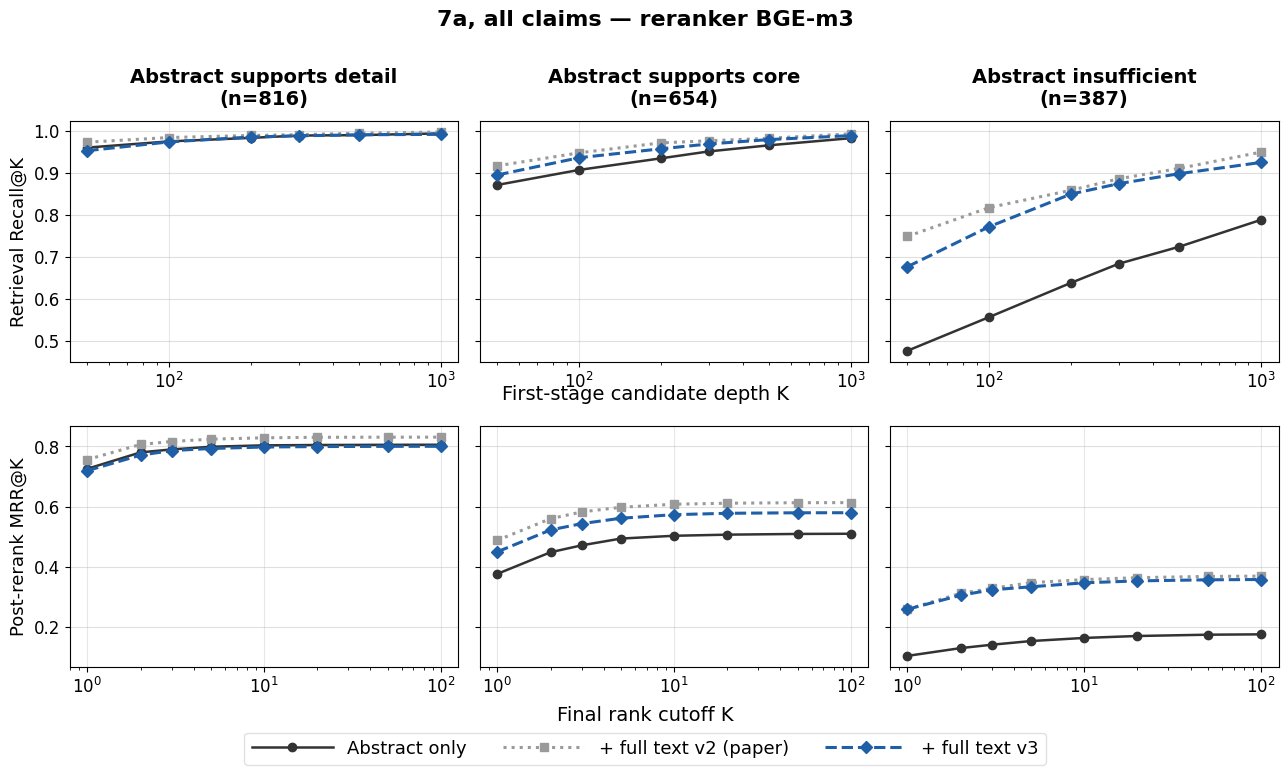

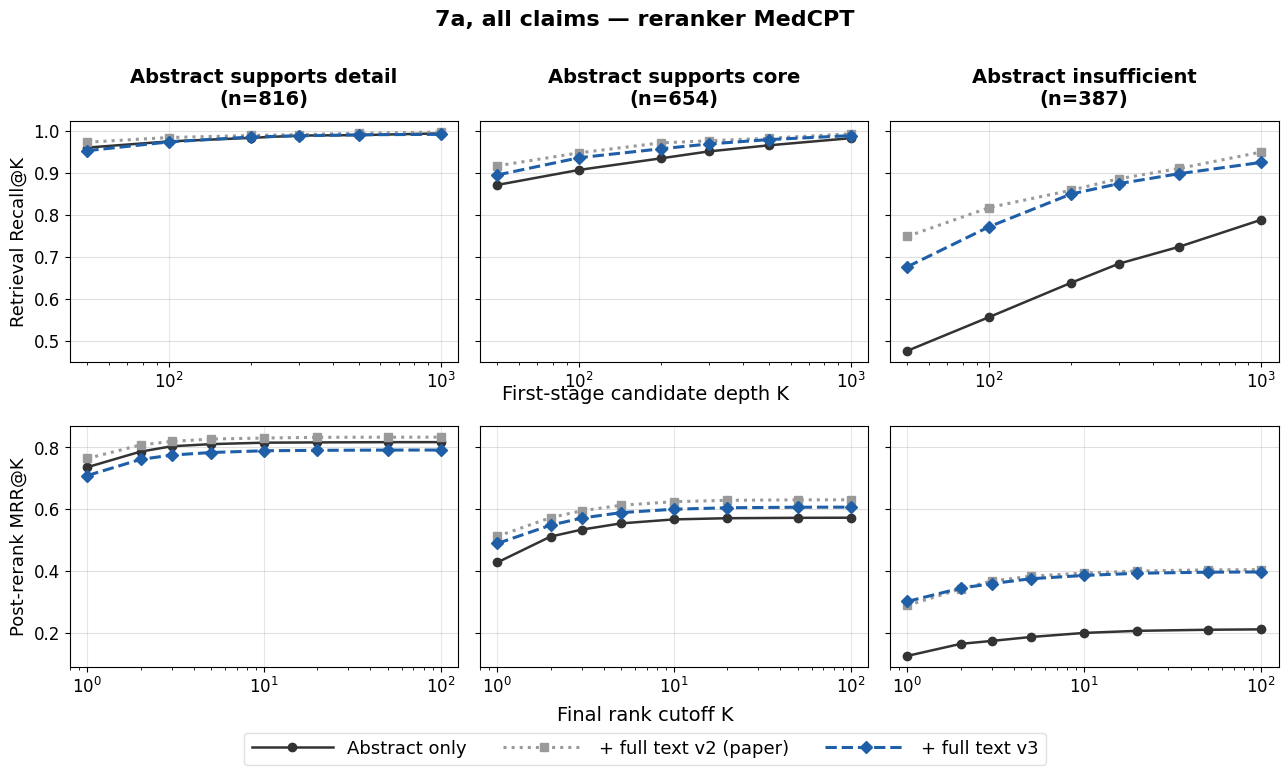

In [6]:
KS_RECALL = [50, 100, 200, 300, 500, 1000]
KS_MRR = [1, 2, 3, 5, 10, 20, 50, 100]
STYLES = {
    "Abstract only": dict(color="#333333", linestyle="-", linewidth=1.8, marker="o", markersize=6),
    "+ full text v2 (paper)": dict(color="#9a9a9a", linestyle=":", linewidth=2.2, marker="s", markersize=6),
    "+ full text v3": dict(color="#1f5fa8", linestyle="--", linewidth=2.2, marker="D", markersize=6),
}


def curve(q, run, fn, ks):
    qs = [x for x in q if x in run]
    return [np.mean([fn(run[x], q[x], k) for x in qs]) for k in ks]


def plot_overlay(systems, qrels_by_level, out_name, suptitle=None):
    fig, axes = plt.subplots(2, 3, figsize=(13.0, 7.8), sharey="row")
    for j, lvl in enumerate(LEVELS):
        q = qrels_by_level[lvl]
        for label, (ret, fin) in systems.items():
            axes[0, j].plot(KS_RECALL, curve(q, ret, recall_at, KS_RECALL), **STYLES[label])
            axes[1, j].plot(KS_MRR, curve(q, fin, mrr_at, KS_MRR), **STYLES[label])
        axes[0, j].set_title(f"{LEVEL_LABELS[lvl]}\n(n={len(q)})", fontweight="bold", fontsize=14, pad=12)
        for ax in axes[:, j]:
            ax.set_xscale("log")
            ax.grid(True, axis="y", alpha=0.4)
            ax.grid(True, axis="x", alpha=0.3)
    axes[0, 0].set_ylabel("Retrieval Recall@K")
    axes[1, 0].set_ylabel("Post-rerank MRR@K")
    handles = [Line2D([0, 1], [0, 0], label=k, **v) for k, v in STYLES.items() if k in systems]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=13, frameon=True,
               edgecolor="0.85", handlelength=4.5, bbox_to_anchor=(0.5, 0.0))
    if suptitle:
        fig.suptitle(suptitle, fontsize=16, fontweight="bold")
    plt.tight_layout(rect=[0, 0.08, 1, 0.97 if suptitle else 1], h_pad=2.5)
    fig.text(0.5, (axes[0, 1].get_position().y0 + axes[1, 1].get_position().y1) / 2,
             "First-stage candidate depth K", ha="center", va="center", fontsize=14)
    fig.text(0.5, 0.075, "Final rank cutoff K", ha="center", va="center", fontsize=14)
    plt.savefig(FIG_DIR / out_name, dpi=150, bbox_inches="tight")
    plt.show()


by_level_7a = qrels("7a")[0]
for rr in RERANKERS:
    systems = {"Abstract only": system("7a_abs", rr),
               "+ full text v2 (paper)": system("paper_v2", rr),
               "+ full text v3": system("7a_v3", rr)}
    plot_overlay(systems, by_level_7a, f"fig_overlay_7a_{rr}.png",
                 suptitle=f"7a, all claims — reranker {RERANKERS[rr]}")

## 5. Table S2 re-check: v3 by evidence stratum and v3 coverage

Same layout as Table S2 (has-PDF / no-PDF by v3 coverage). † = CI crosses zero.

In [7]:
s2 = {}
for rr in RERANKERS:
    s2[rr] = compare(system("7a_abs", rr), system("7a_v3", rr), cov=COV["v3"])
    display(Markdown(f"**{RERANKERS[rr]} — abstract only (Abs) vs + v3 full text (+Chk)**\n\n" + s2_table(s2[rr])))

**BGE-m3 — abstract only (Abs) vs + v3 full text (+Chk)**

| Coverage | Evidence stratum | n | R@1000 Abs | R@1000 +Chk (Δ [95% CI]) | MRR@10 Abs | MRR@10 +Chk (Δ [95% CI]) |
| --- | --- | --- | --- | --- | --- | --- |
| all | Detail | 816 | 0.993 | 0.991 (-0.2 [-0.9, +0.4]†) | 0.803 | 0.798 (-0.6 [-2.5, +1.4]†) |
| has-PDF | Detail | 761 | 0.993 | 0.995 (+0.2 [-0.3, +0.8]†) | 0.810 | 0.817 (+0.7 [-1.3, +2.7]†) |
| no-PDF | Detail | 55 | 1.000 | 0.945 (-5.5 [-12.7, +0.0]†) | 0.714 | 0.536 (-17.8 [-26.0, -10.4]) |
| all | Core | 654 | 0.982 | 0.988 (+0.6 [-0.3, +1.6]†) | 0.503 | 0.573 (+7.0 [+4.1, +9.9]) |
| has-PDF | Core | 618 | 0.983 | 0.995 (+1.2 [+0.5, +2.2]) | 0.505 | 0.593 (+8.8 [+5.9, +11.9]) |
| no-PDF | Core | 36 | 0.972 | 0.889 (-8.3 [-19.4, +0.0]†) | 0.395 | 0.184 (-21.0 [-29.8, -13.0]) |
| all | Insufficient | 387 | 0.788 | 0.924 (+13.7 [+9.8, +17.6]) | 0.163 | 0.346 (+18.3 [+14.5, +22.3]) |
| has-PDF | Insufficient | 369 | 0.787 | 0.944 (+15.7 [+11.8, +19.6]) | 0.164 | 0.363 (+19.9 [+16.0, +23.8]) |
| no-PDF | Insufficient | 18 | 0.778 | 0.500 (-27.8 [-50.0, -11.1]) | 0.119 | 0.006 (-11.3 [-23.8, -1.6]) |
| all | All claims | 1656 | 0.950 | 0.978 (+2.8 [+1.8, +3.7]) | 0.620 | 0.685 (+6.5 [+4.8, +8.2]) |

**MedCPT — abstract only (Abs) vs + v3 full text (+Chk)**

| Coverage | Evidence stratum | n | R@1000 Abs | R@1000 +Chk (Δ [95% CI]) | MRR@10 Abs | MRR@10 +Chk (Δ [95% CI]) |
| --- | --- | --- | --- | --- | --- | --- |
| all | Detail | 816 | 0.993 | 0.991 (-0.2 [-0.9, +0.4]†) | 0.814 | 0.788 (-2.6 [-4.5, -0.7]) |
| has-PDF | Detail | 761 | 0.993 | 0.995 (+0.2 [-0.3, +0.8]†) | 0.823 | 0.808 (-1.5 [-3.4, +0.4]†) |
| no-PDF | Detail | 55 | 1.000 | 0.945 (-5.5 [-12.7, +0.0]†) | 0.690 | 0.504 (-18.6 [-26.3, -11.4]) |
| all | Core | 654 | 0.982 | 0.988 (+0.6 [-0.3, +1.6]†) | 0.567 | 0.600 (+3.3 [+0.6, +6.0]) |
| has-PDF | Core | 618 | 0.983 | 0.995 (+1.2 [+0.5, +2.2]) | 0.570 | 0.617 (+4.7 [+1.9, +7.5]) |
| no-PDF | Core | 36 | 0.972 | 0.889 (-8.3 [-19.4, +0.0]†) | 0.446 | 0.253 (-19.2 [-27.3, -11.9]) |
| all | Insufficient | 387 | 0.788 | 0.924 (+13.7 [+9.8, +17.6]) | 0.201 | 0.386 (+18.5 [+14.7, +22.5]) |
| has-PDF | Insufficient | 369 | 0.787 | 0.944 (+15.7 [+11.8, +19.6]) | 0.199 | 0.402 (+20.4 [+16.5, +24.4]) |
| no-PDF | Insufficient | 18 | 0.778 | 0.500 (-27.8 [-50.0, -11.1]) | 0.185 | 0.044 (-14.2 [-27.8, -3.7]) |
| all | All claims | 1656 | 0.950 | 0.978 (+2.8 [+1.8, +3.7]) | 0.657 | 0.700 (+4.2 [+2.7, +5.9]) |

Share of claims whose MRR@10 rises / falls with v3 full text (paper, BGE-m3 has-PDF
insufficient: 46.9% up, 8.0% down).

In [8]:
display(pd.concat({RERANKERS[rr]: s2[rr].set_index(["stratum", "part"])[["n", "pct_up", "pct_down"]]
                   for rr in RERANKERS}, axis=1).round(1))

BGE-m3                 MedCPT                
                          n pct_up pct_down      n pct_up pct_down
stratum      part                                                 
Detail       all        816   12.3     16.9    816   11.4     18.8
             has-PDF    761   13.0     15.2    761   11.8     17.0
             no-PDF      55    1.8     40.0     55    5.5     45.5
Core         all        654   30.3     23.9    654   24.8     25.7
             has-PDF    618   32.2     21.8    618   26.2     24.3
             no-PDF      36    2.8     58.3     36    0.0     52.8
Insufficient all        387   40.1      9.8    387   38.8     12.4
             has-PDF    369   42.0      8.9    369   40.7     10.8
             no-PDF      18    0.0     22.2     18    0.0     38.9
All claims   all       1656   24.5     16.9   1656   21.3     18.4

## 6. Why the gains are smaller: coverage, not chunking

v3 differs from v2 in coverage and in chunking. To separate them, drop from the v3 runs the
full-text chunks of every article that had no v2 full text ("v3 chunks, v2 coverage"), and
score all three full-text systems on the paper's has-PDF sets (v2 coverage). This is a
post-hoc filter of the ranked lists, not a fresh run.

If filtered v3 matches the paper, v3's chunking behaves like v2's and the smaller v3 gain
comes from distractor articles now having full text too. All deltas here are against the
rerun abstract arm, so the paper's own values shift by up to 0.1 point (e.g. +22.6 here vs
+22.5 in Table S2).

In [9]:
DECOMP = {"Paper (v2)": "paper_v2", "v3 chunks, v2 coverage": "v3_v2cov", "v3": "7a_v3"}
decomp_rows = []
for rr in RERANKERS:
    base = system("7a_abs", rr)
    for label, key in DECOMP.items():
        other = system("7a_v3", rr, keep_pmids=COV["v2"]) if key == "v3_v2cov" else system(key, rr)
        df = compare(base, other, cov=COV["v2"], parts=("has-PDF",))
        decomp_rows.append(df.assign(reranker=RERANKERS[rr], system=label))
decomp = pd.concat(decomp_rows, ignore_index=True)
decomp["row"] = np.where(decomp.stratum == "All claims", "All claims", decomp.stratum + ", has-PDF")
display(decomp.pivot_table(index=["reranker", "row"], columns="system", values="dMRR10", sort=False)
        [list(DECOMP)].round(1))

system                          Paper (v2)  v3 chunks, v2 coverage    v3
reranker row                                                            
BGE-m3   Detail, has-PDF               4.2                     3.2   0.6
         Core, has-PDF                13.1                    13.1   7.9
         Insufficient, has-PDF        22.6                    24.4  19.3
         All claims                    9.3                     9.3   6.5
MedCPT   Detail, has-PDF               2.9                     1.5  -1.7
         Core, has-PDF                 8.4                     8.7   3.9
         Insufficient, has-PDF        22.6                    23.9  19.5
         All claims                    7.2                     6.9   4.2

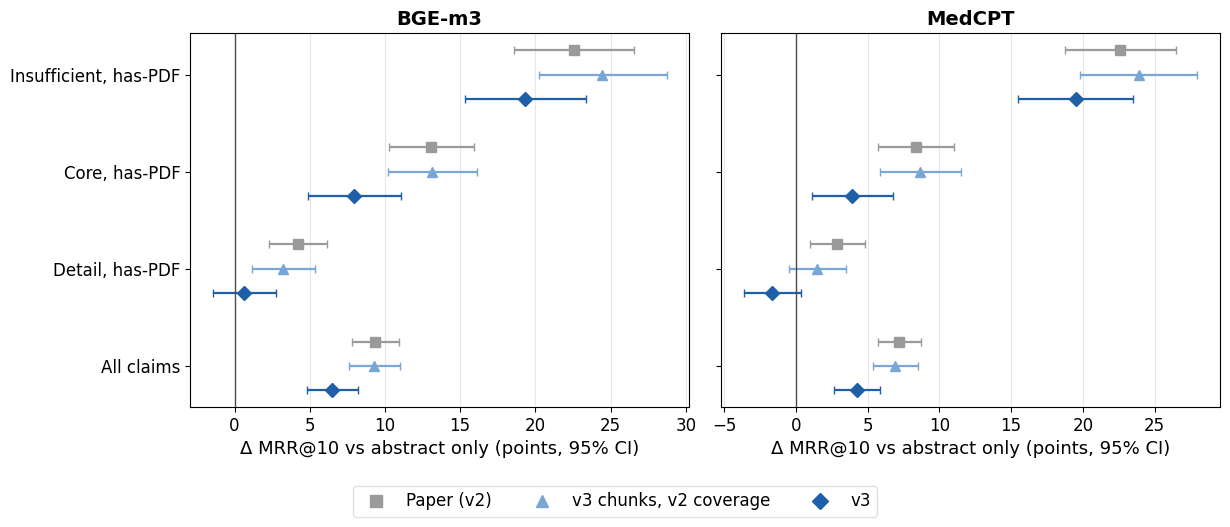

In [10]:
ROW_ORDER = ["Insufficient, has-PDF", "Core, has-PDF", "Detail, has-PDF", "All claims"]
SYS_STYLE = {"Paper (v2)": ("#9a9a9a", "s"), "v3 chunks, v2 coverage": ("#7aa6d6", "^"), "v3": ("#1f5fa8", "D")}


def forest(df, row_col, rows, group_col, groups, styles, title_col, titles, out_name, xlabel):
    fig, axes = plt.subplots(1, len(titles), figsize=(6.2 * len(titles), 0.9 * len(rows) + 1.6), sharey=True)
    axes = np.atleast_1d(axes)
    off = np.linspace(-0.25, 0.25, len(groups))
    for ax, t in zip(axes, titles):
        sub = df[df[title_col] == t]
        for o, g in zip(off, groups):
            color, marker = styles[g]
            for i, r in enumerate(rows):
                x = sub[(sub[row_col] == r) & (sub[group_col] == g)]
                if x.empty:
                    continue
                x = x.iloc[0]
                ax.errorbar(x.dMRR10, i + o, xerr=[[x.dMRR10 - x.dMRR10_lo], [x.dMRR10_hi - x.dMRR10]],
                            fmt=marker, color=color, ms=7, capsize=3, lw=1.6)
        ax.axvline(0, color="0.3", lw=1)
        ax.set_yticks(range(len(rows)), rows)
        ax.set_title(t, fontweight="bold")
        ax.set_xlabel(xlabel)
        ax.grid(True, axis="x", alpha=0.3)
    axes[0].invert_yaxis()
    handles = [Line2D([], [], color=styles[g][0], marker=styles[g][1], ls="", ms=8, label=g) for g in groups]
    fig.legend(handles=handles, loc="lower center", ncol=len(groups), fontsize=12, frameon=True,
               edgecolor="0.85", bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.savefig(FIG_DIR / out_name, dpi=150, bbox_inches="tight")
    plt.show()


forest(decomp, "row", ROW_ORDER, "system", list(DECOMP), SYS_STYLE, "reranker", list(RERANKERS.values()),
       "fig_decomposition_7a.png", "Δ MRR@10 vs abstract only (points, 95% CI)")

## 7. Full text vs abstract under query expansion (7d, 563 claims)

Three query variants, each run end to end on both corpora: no expansion (the 7a runs
restricted to the 563 7d claims; their query text and gold are identical), +synonyms, and
+synonyms & products (the expanded text drives BM25, dense retrieval and the reranker).

In [11]:
q7d = qrels("7d")[1]
assert all(qrels("7a")[1][x] == q7d[x] for x in q7d)
QE = {"No expansion": "7a", "+synonyms": "7d_syn", "+synonyms & products": "7d_synprod"}
qe_rows = []
for rr in RERANKERS:
    for qe, pre in QE.items():
        split = "7a" if pre == "7a" else "7d"
        df = compare(system(f"{pre}_abs", rr), system(f"{pre}_v3", rr), split=split, qids=set(q7d), parts=("all",))
        qe_rows.append(df.assign(reranker=RERANKERS[rr], query=qe))
qe = pd.concat(qe_rows, ignore_index=True)

summary = qe[qe.stratum == "All claims"].assign(
    **{"MRR@10 Abs": lambda d: d.MRR10_base.map("{:.3f}".format),
       "MRR@10 +v3 (Δ [95% CI])": lambda d: [f"{b:.3f} ({fmt_delta(x, lo, hi)})" for b, x, lo, hi in
                                             zip(d.MRR10_other, d.dMRR10, d.dMRR10_lo, d.dMRR10_hi)],
       "R@1000 Abs": lambda d: d.R1000_base.map("{:.3f}".format),
       "R@1000 +v3": lambda d: d.R1000_other.map("{:.3f}".format)})
display(Markdown(md(summary[["reranker", "query", "n", "MRR@10 Abs", "MRR@10 +v3 (Δ [95% CI])", "R@1000 Abs", "R@1000 +v3"]])))

| reranker | query | n | MRR@10 Abs | MRR@10 +v3 (Δ [95% CI]) | R@1000 Abs | R@1000 +v3 |
| --- | --- | --- | --- | --- | --- | --- |
| BGE-m3 | No expansion | 563 | 0.589 | 0.668 (+7.9 [+4.9, +11.1]) | 0.948 | 0.980 |
| BGE-m3 | +synonyms | 563 | 0.643 | 0.689 (+4.6 [+1.7, +7.6]) | 0.976 | 0.989 |
| BGE-m3 | +synonyms & products | 563 | 0.646 | 0.676 (+3.0 [+0.3, +5.6]) | 0.983 | 0.995 |
| MedCPT | No expansion | 563 | 0.623 | 0.673 (+5.0 [+2.0, +8.0]) | 0.948 | 0.980 |
| MedCPT | +synonyms | 563 | 0.692 | 0.708 (+1.6 [-1.1, +4.3]†) | 0.976 | 0.989 |
| MedCPT | +synonyms & products | 563 | 0.680 | 0.697 (+1.7 [-0.9, +4.3]†) | 0.983 | 0.995 |

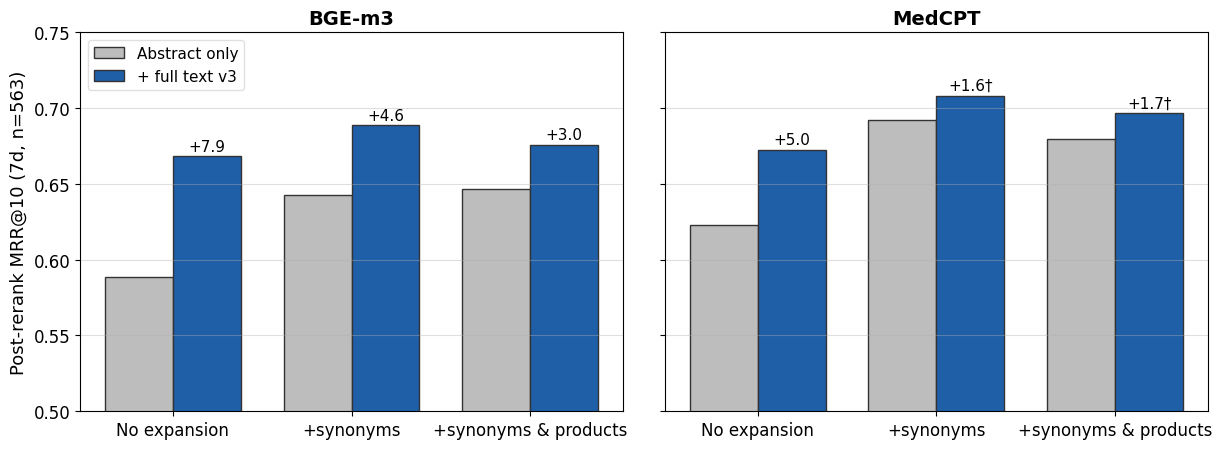

Labels: Δ in points, full text minus abstract; † = 95% CI crosses zero.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
x = np.arange(len(QE))
for ax, rr in zip(axes, RERANKERS.values()):
    s = summary[summary.reranker == rr].set_index("query").loc[list(QE)]
    ax.bar(x - 0.19, s.MRR10_base, 0.38, color="#bdbdbd", edgecolor="#333333", label="Abstract only")
    ax.bar(x + 0.19, s.MRR10_other, 0.38, color="#1f5fa8", edgecolor="#333333", label="+ full text v3")
    for xi, (_, r) in zip(x, s.iterrows()):
        dag = "†" if r.dMRR10_lo <= 0 <= r.dMRR10_hi else ""
        ax.annotate(f"{r.dMRR10:+.1f}{dag}", (xi + 0.19, r.MRR10_other), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=11)
    ax.set_xticks(x, list(QE))
    ax.set_title(rr, fontweight="bold")
    ax.set_ylim(0.5, 0.75)
    ax.grid(True, axis="y", alpha=0.4)
axes[0].set_ylabel("Post-rerank MRR@10 (7d, n=563)")
axes[0].legend(loc="upper left", fontsize=11, frameon=True, edgecolor="0.85")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_qe_mrr10_7d.png", dpi=150, bbox_inches="tight")
plt.show()
print("Labels: Δ in points, full text minus abstract; † = 95% CI crosses zero.")

Per evidence stratum, Δ MRR@10 (+v3 − abstract) under each query variant:

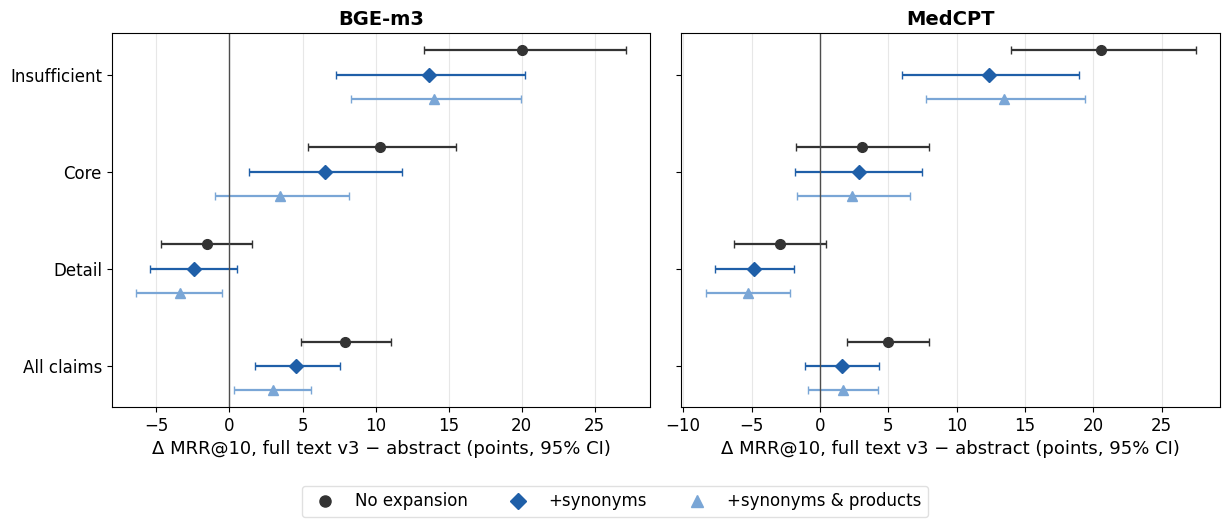

In [13]:
QE_STYLE = {"No expansion": ("#333333", "o"), "+synonyms": ("#1f5fa8", "D"), "+synonyms & products": ("#7aa6d6", "^")}
qe["row"] = qe.stratum
forest(qe, "row", ["Insufficient", "Core", "Detail", "All claims"], "query", list(QE), QE_STYLE,
       "reranker", list(RERANKERS.values()), "fig_qe_strata_7d.png", "Δ MRR@10, full text v3 − abstract (points, 95% CI)")

Query expansion and full text overlap. The table gives the effect of each expansion on its
own corpus, and the combination against plain abstract search.

In [14]:
qe_eff = []
for rr in RERANKERS:
    for corpus_ in ["abs", "v3"]:
        for qe_, pre in list(QE.items())[1:]:
            df = compare(system(f"7a_{corpus_}", rr), system(f"{pre}_{corpus_}", rr), split="7d",
                         qids=set(q7d), parts=())
            r = df[df.stratum == "All claims"].iloc[0]
            qe_eff.append({"Reranker": RERANKERS[rr], "Comparison": f"{qe_} vs no expansion, {'abstract' if corpus_ == 'abs' else 'full text v3'}",
                           "MRR@10": f"{r.MRR10_base:.3f} → {r.MRR10_other:.3f}",
                           "Δ [95% CI]": fmt_delta(r.dMRR10, r.dMRR10_lo, r.dMRR10_hi)})
    df = compare(system("7a_abs", rr), system("7d_syn_v3", rr), split="7d", qids=set(q7d), parts=())
    r = df[df.stratum == "All claims"].iloc[0]
    qe_eff.append({"Reranker": RERANKERS[rr], "Comparison": "full text v3 + synonyms vs abstract, no expansion",
                   "MRR@10": f"{r.MRR10_base:.3f} → {r.MRR10_other:.3f}",
                   "Δ [95% CI]": fmt_delta(r.dMRR10, r.dMRR10_lo, r.dMRR10_hi)})
display(Markdown(md(pd.DataFrame(qe_eff))))

| Reranker | Comparison | MRR@10 | Δ [95% CI] |
| --- | --- | --- | --- |
| BGE-m3 | +synonyms vs no expansion, abstract | 0.589 → 0.643 | +5.4 [+3.3, +7.6] |
| BGE-m3 | +synonyms & products vs no expansion, abstract | 0.589 → 0.646 | +5.8 [+3.4, +8.2] |
| BGE-m3 | +synonyms vs no expansion, full text v3 | 0.668 → 0.689 | +2.1 [-0.1, +4.3]† |
| BGE-m3 | +synonyms & products vs no expansion, full text v3 | 0.668 → 0.676 | +0.8 [-1.7, +3.3]† |
| BGE-m3 | full text v3 + synonyms vs abstract, no expansion | 0.589 → 0.689 | +10.0 [+7.0, +13.2] |
| MedCPT | +synonyms vs no expansion, abstract | 0.623 → 0.692 | +6.9 [+4.8, +9.1] |
| MedCPT | +synonyms & products vs no expansion, abstract | 0.623 → 0.680 | +5.7 [+3.3, +8.1] |
| MedCPT | +synonyms vs no expansion, full text v3 | 0.673 → 0.708 | +3.6 [+1.3, +5.9] |
| MedCPT | +synonyms & products vs no expansion, full text v3 | 0.673 → 0.697 | +2.4 [-0.1, +4.9]† |
| MedCPT | full text v3 + synonyms vs abstract, no expansion | 0.623 → 0.708 | +8.5 [+5.3, +11.7] |

## 8. Summary

- **Coverage.** v3 gives cited and uncited articles near-equal full-text coverage; v2 covered
  most cited articles and few uncited ones (§2). No-PDF claim–stratum entries halve, from
  215 to 109 (§2b, update of Table 2).
- **Baseline.** The rerun abstract arm matches the paper's abstract baseline, so the paper's
  comparison was like-for-like in its settings (§3).
- **Do the paper's findings hold?** The direction holds. Full text helps most where the
  abstract is insufficient (about +20 MRR@10 points with either reranker, recall@1000 up
  from about 0.79 to 0.94), and claims whose cited articles lack full text still lose rank.
  The sizes shrink: the core gain falls to between a third and two thirds of the paper's,
  and the paper's detail gain is gone (§4–5).
- **Why.** Restricting v3's chunks to v2's coverage brings back the paper's numbers, so v3's
  chunking is not the cause. Part of the paper's gain came from cited articles having full
  text while most distractors did not (§6).
- **Does full text help overall?** Yes, modestly: about +6.5 (BGE-m3) and +4 (MedCPT)
  MRR@10 points across all 1656 claims, almost all of it from claims whose evidence is not
  in the abstract (§5).
- **With query expansion.** Full text and gene-aware expansion are partial substitutes. Each
  helps on its own; together they add less than the sum. With expanded queries the overall
  full-text gain shrinks (BGE-m3) or loses significance (MedCPT). The gain on
  abstract-insufficient claims shrinks from about +20 to +12–14 points but stays clearly
  positive, while detail claims lose slightly (§7).